In [53]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 1 - Diffusive and dispersive properties of the advection schemes

## Aim of Tutorial

The aim of this tutorial is to give the readers an opportunity to run the salt block simulation using the different advection schemes. Here we choose to use the transport of a block of salt to demonstrate how the diffusive and dispersive properties of the advection scheme impact the outcome of a simulation.

To run this demonstrator you must have followed Tutorial 1 beforehand.

## Dispersive scheme 

### Running the simulation

An example of a dispersive scheme in NEMO 5.0 is the CENtred advection scheme (CEN).
To run a CEN2 simulation, we need to change ```ln_traadv_cen``` from ```.false.``` to ```.true.``` and ```nn_cen_h``` and ```nn_cen_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [54]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_cen2_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/

bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/cen2_cfg.sh "$DIR"


rn_salszx, rn_salszy already in the file, insertion ignored.
57c57
<    cn_exp =	'CANAL_saltblock_cen2'			                  		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'			                  		 !  experience name
57c57
<    cn_exp =	'CANAL_saltblock_cen2'				                  		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'			                  		 !  experience name



real	3m52.798s
user	5m16.761s
sys	1m9.756s



Everything looks good

Run CANAL_saltblock_cen2_all_grid.nc completed


In [55]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_cen4_all_grid.nc

bash /"$DIR"/demo1_cfg/cen4_cfg.sh "$DIR"


57c57
<    cn_exp =	'CANAL_saltblock_cen4'					                  		 !  experience name
---
>    cn_exp =	'CANAL_saltblock_cen2'				                  		 !  experience name
167,168c167,168
<       nn_cen_h	=	4		!  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v  =       4		!  =2/4, vertical   2nd order CEN / 4th order COMPACT
---
>       nn_cen_h	=	2		!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v  =       2		!  =2/4, vertical   2nd order CEN / 4th order COMPACT



real	3m47.486s
user	5m21.879s
sys	1m10.642s



Everything looks good

Run CANAL_saltblock_cen4_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .true. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_cen2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [60]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


cen2 = xr.open_dataset(rep+'CANAL_saltblock_cen2_all_grid.nc')
cen4 = xr.open_dataset(rep+'CANAL_saltblock_cen4_all_grid.nc', decode_times=False)

## Diffusive scheme 

### Running the simulation

An example of a diffusive scheme in NEMO 5.0 is the Upstream Biased Scheme (UBS).
To run a UBS simulation, we need to change ```ln_traadv_ubs``` from ```.false.``` to ```.true.``` in the namelist and set ```nn_ubs_v``` to ```2```.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [80]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_ubs_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/


bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/ubs_cfg.sh "$DIR"


rn_salszx, rn_salszy already in the file, insertion ignored.
57c57
<    cn_exp =	'CANAL_saltblock_cen4'					                  		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'					                  		 !  experience name
57c57
<    cn_exp =  'CANAL_saltblock_ubs'      					                  		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'					                  		 !  experience name
165,166c165,166
<    ln_traadv_OFF        =       .false. !  No tracer advection
<    ln_traadv_cen        =       .false. !  2nd order centered scheme
---
>    ln_traadv_OFF	=	.false.	!  No tracer advection
>    ln_traadv_cen	=	.true.	!  2nd order centered scheme
169c169
<    ln_traadv_fct        =       .false. !  FCT scheme
---
>    ln_traadv_fct	=	.false.	!  FCT scheme
172c172
<    ln_traadv_mus        =       .false. !  MUSCL scheme
---
>    ln_traadv_mus	=	.false.	!  MUSCL scheme
174c174
<    ln_traadv_ubs        =       .true.  !  UBS scheme
---
>    ln_traadv_ubs	=	.false.	!  UBS sche


real	3m37.231s
user	5m20.303s
sys	1m6.106s



Everything looks good

Run CANAL_saltblock_ubs_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .true.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_ubs``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

In [87]:
#Open the simulation using the xr library

ubs = xr.open_dataset(rep+'CANAL_saltblock_ubs_all_grid.nc')

## Corrected scheme 

### Running the simulation

An example of a corrected scheme in NEMO 5.0 is the Flux Corrected Transport scheme (FCT).
To run a FCT simulation, we need to change ```ln_traadv_fct``` from ```.false.``` to ```.true.``` and the ```nn_fct_h``` and ```nn_fct_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [91]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_fct2_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/


bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/fct2_cfg.sh "$DIR"

rn_salszx, rn_salszy already in the file, insertion ignored.
57c57
<    cn_exp =  'CANAL_saltblock_ubs'      					                  		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'      					                  		 !  experience name
57c57
<    cn_exp =  'CANAL_saltblock_fct2'            					                  		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'      					                  		 !  experience name
169,171c169,171
<    ln_traadv_fct        =       .true.  !  FCT scheme
<       nn_fct_h  =       2               !  =2/4, horizontal 2nd / 4th order
<       nn_fct_v  =       2               !  =2/4, vertical   2nd / COMPACT 4th order
---
>    ln_traadv_fct        =       .false. !  FCT scheme
>       nn_fct_h  =       4               !  =2/4, horizontal 2nd / 4th order
>       nn_fct_v  =       4               !  =2/4, vertical   2nd / COMPACT 4th order
174c174
<    ln_traadv_ubs        =       .false. !  UBS scheme
---
>    ln_traadv_ubs        =       .true.  !  U


real	4m0.010s
user	5m31.121s
sys	1m13.534s



Everything looks good

Run CANAL_saltblock_fct2_all_grid.nc completed


In [92]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_fct4_all_grid.nc

bash /"$DIR"/demo1_cfg/fct4_cfg.sh "$DIR"

57c57
<    cn_exp =  'CANAL_saltblock_fct4'                  					                  		 !  experience name
---
>    cn_exp =  'CANAL_saltblock_fct2'            					                  		 !  experience name
170,171c170,171
<       nn_fct_h  =       4               !  =2/4, horizontal 2nd / 4th order
<       nn_fct_v  =       4               !  =2/4, vertical   2nd / COMPACT 4th order
---
>       nn_fct_h  =       2               !  =2/4, horizontal 2nd / 4th order
>       nn_fct_v  =       2               !  =2/4, vertical   2nd / COMPACT 4th order



real	4m9.462s
user	5m40.763s
sys	1m15.931s



Everything looks good

Run CANAL_saltblock_fct2_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .true. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_fct2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

In [93]:
fct2 = xr.open_dataset(rep+'CANAL_saltblock_fct2_all_grid.nc')
fct4 = xr.open_dataset(rep+'CANAL_saltblock_fct4_all_grid.nc')

## Comparative plots

In [94]:
block_0 = xr.open_dataset(rep+'CANAL_saltblock_traadvOFF_all_grid.nc', decode_times=False)
block_0 =block_0.soce.isel(y_grid_T = 50, time_counter=0, deptht=0)

v= 0.5
dx = 10000
dt = 3600
ref = []


for t in range (80):
    ref.append(np.roll(block_0, shift=v*dt*(t+1)/dx))


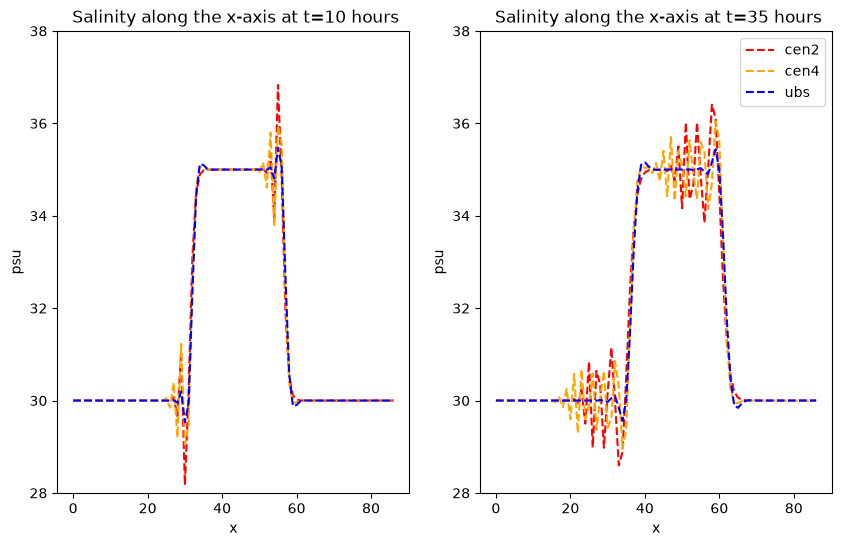

In [95]:
t0, t1 = 9, 34

fig, ax = plt.subplots(1, 2, figsize=(10,6))

ax[0].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
ax[0].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_ylim(28,38)
ax[0].set_title(f' Salinity along the x-axis at t={t0+1} hours')

ax[1].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
ax[1].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_ylim(28,38)
ax[1].set_title(f' Salinity along the x-axis at t={t1+1} hours')

plt.legend()

In [96]:
block_0 = xr.open_dataset(rep+'CANAL_saltblock_traadvOFF_all_grid.nc').sssgrad.isel(y_grid_T = 50, time_counter = 0)

ref_grad = []

for t in range (80):
    ref_grad.append(np.roll(block_0, shift=v*86400*(t+0.5)/dx)) 
    """ce 0.5 me pose probleme, cela veut dire que soit la sortie 
        est prise en milieu de journee pas en fin de journee comme on avait convenu
        normalement ce n'est pas la moyenne de la journee c'est sur car j'ai bien verifie 
        dans def_field qu'on etait en operation=instant"""




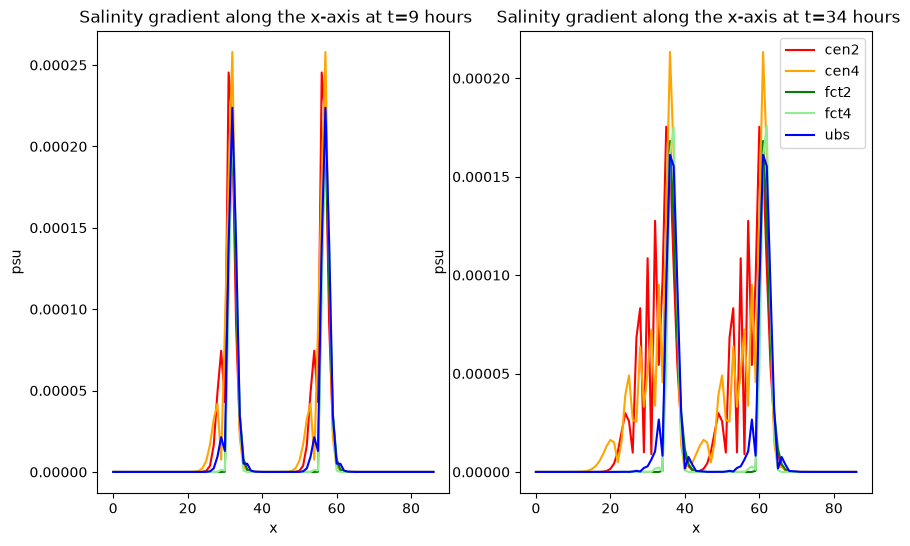

In [110]:
t0, t1 = 9, 34

fig, ax = plt.subplots(1, 2, figsize=(10,6))

ax[0].plot(np.arange(cen2['sssgrad'].shape[2]), cen2['sssgrad'].isel(time_counter=t0, y_grid_T=50), color ='red', label = 'cen2')
ax[0].plot(np.arange(cen4['sssgrad'].shape[2]), cen4['sssgrad'].isel(time_counter=t0, y_grid_T=50), color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=t0, y_grid_T=50), color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=t0, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=t0, y_grid_T=50), color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_title(f' Salinity gradient along the x-axis at t={t0} hours')


ax[1].plot(np.arange(cen2['sssgrad'].shape[2]), cen2['sssgrad'].isel(time_counter=t1, y_grid_T=50), color ='red', label = 'cen2')
ax[1].plot(np.arange(cen4['sssgrad'].shape[2]), cen4['sssgrad'].isel(time_counter=t1, y_grid_T=50), color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=t1, y_grid_T=50), color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=t1, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=t1, y_grid_T=50), color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_title(f' Salinity gradient along the x-axis at t={t1} hours')

plt.legend()

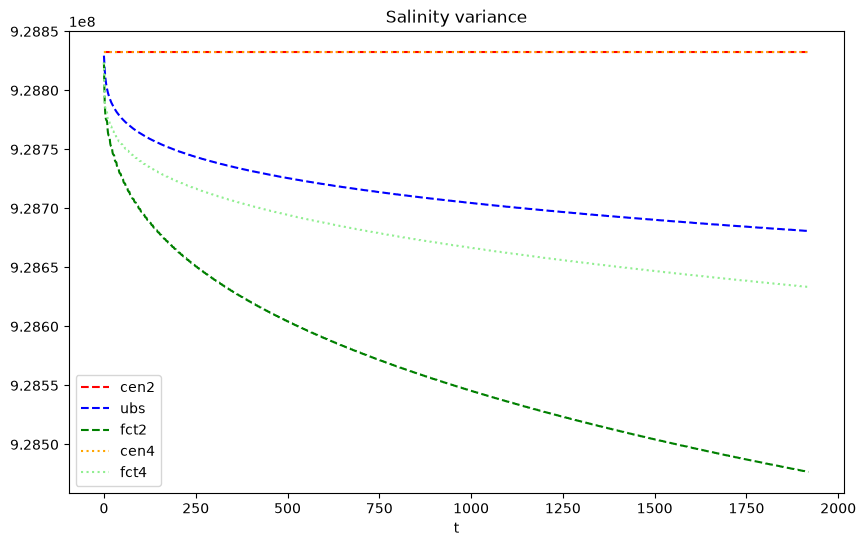

In [98]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))

s2c = cen2['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, '--', color = 'red', label = 'cen2')

s2c = ubs['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, '--', color = 'blue', label = 'ubs')

s2c = fct2['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, '--', color = 'green', label = 'fct2')

s2c = cen4['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, ':', color = 'orange', label = 'cen4')

s2c = fct4['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, ':', color = 'lightgreen', label = 'fct4')


axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()

In [99]:
#cen2 = xr.open_dataset(rep+'CANAL_phase_speed_all_grid.nc')
#cen4 = xr.open_dataset(rep+'CANAL_phase_speed4_all_grid.nc')
#cen4

In [105]:
dx, dt, c0 = 10000., 3600., 0.5
x0, nt = 43, 20
levels = [0.05*k for k in range(1, 21)]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(levels)))

schemes = {'cen2': cen2, 'cen4': cen4, 'ubs': ubs}
fields = {n: ds['soce'].isel(y_grid_T=50, deptht=0, time_counter=slice(0, nt)).values - 35
          for n, ds in schemes.items()}
nx = next(iter(fields.values())).shape[1]
L = nx*dx/1e3                                  # longueur du domaine (km)
t = np.arange(nt)*dt


/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_34344/3960817051.py:11: RuntimeWarning: divide by zero encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_34344/3960817051.py:11: RuntimeWarning: invalid value encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy


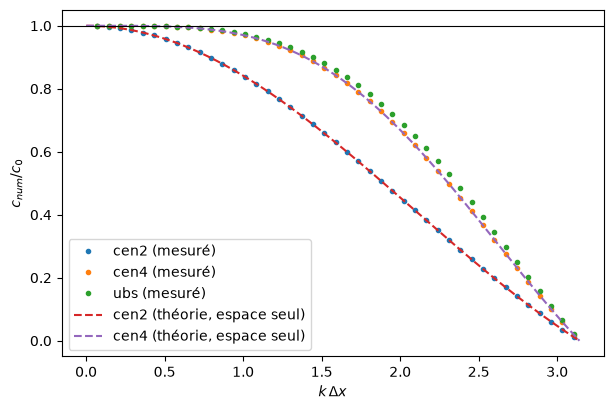

In [106]:
dx = 10000 #[m]
dt = 3600 #[s]
c0 = 0.5 #[m/s]
theta_max = min(np.pi, np.pi*dx/(c0*dt))
k_max = theta_max/dx

def phase_speed(f, dx, dt):
    """f[t, x] -> k, c(k) mesuré par la rotation de phase entre pas de temps."""
    F = np.fft.rfft(f - f.mean(axis=1, keepdims=True), axis=1)
    k = 2*np.pi*np.fft.rfftfreq(f.shape[1], dx)
    dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy
    w = np.abs(F[1:] * F[:-1])               # pondération par l'amplitude
    c = np.full(k.shape, np.nan)
    for i in range(1, len(k)):
        c[i] = -np.sum(w[:, i] * dphi[:, i]) / (np.sum(w[:, i]) * k[i] * dt)
    return k, c

theta = np.linspace(1e-3, theta_max, 400)                       # θ = k·dx
theory = {
    'cen2': np.sin(theta) / theta,
    'cen4': (4/3*np.sin(theta) - 1/6*np.sin(2*theta)) / theta,
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, f in fields.items():
    k, c = phase_speed(f, dx, dt)
    k=k[ k < k_max]
    c = c[:len(k)]
    ax.plot(k*dx, c / c0, '.', label=f'{name} (mesuré)')
for name, c_th in theory.items():
    ax.plot(theta, c_th, '--', label=f'{name} (théorie, espace seul)')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel(r'$k\,\Delta x$')
ax.set_ylabel(r'$c_{num}/c_0$')
ax.legend()
plt.show()

In [107]:
from matplotlib.colors import LogNorm

dx, dt, c0, xs = 10000., 24*3600., 0.5, 43     # xs : indice de la source, à ajuster
nt = 40
g = {n: ds['sssgrad'].isel(y_grid_T=50, time_counter=slice(0, nt)).values
     for n, ds in schemes.items()}


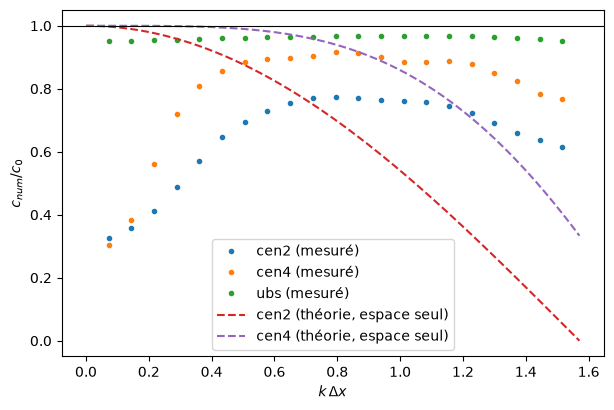

In [108]:
dx = 10000 #[m]
dt = 3600 #[s]
c0 = 0.5 #[m/s]
theta_max = min(np.pi/2, np.pi*dx/(c0*dt))
k_max = theta_max/dx

def phase_speed(f, dx, dt):
    """f[t, x] -> k, c(k) mesuré par la rotation de phase entre pas de temps."""
    F = np.fft.rfft(f - f.mean(axis=1, keepdims=True), axis=1)
    k = 2*np.pi*np.fft.rfftfreq(f.shape[1], dx)
    dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy
    w = np.abs(F[1:] * F[:-1])               # pondération par l'amplitude
    c = np.full(k.shape, np.nan)
    for i in range(1, len(k)):
        c[i] = -np.sum(w[:, i] * dphi[:, i]) / (np.sum(w[:, i]) * k[i] * dt)
    return k, c

theta = np.linspace(1e-3, theta_max, 400)                       # θ = k·dx
theory = {
    'cen2': np.cos(theta),
    'cen4': (4/3*np.cos(theta) - 1/3*np.cos(2*theta)),
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, f in g.items():
    k, c = phase_speed(f, dx, dt)
    k=k[ k*dx < theta_max]
    c = c[:len(k)]
    ax.plot(k*dx, c / c0, '.', label=f'{name} (mesuré)')
for name, c_th in theory.items():
    ax.plot(theta, c_th, '--', label=f'{name} (théorie, espace seul)')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel(r'$k\,\Delta x$')
ax.set_ylabel(r'$c_{num}/c_0$')
ax.legend()
plt.show()

In [104]:
cen2.close()
ubs.close()
fct2.close()